<a href="https://colab.research.google.com/github/abdelrahmanhela/Smart-Used-Car-Selection-and-Pricing-System/blob/main/Random_Forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('/content/cars_clean.csv')
df.head()

,id,make,model,year,km,price_egp,transmission,color,city,seller_type,fuel_type
0,7284417,Toyota,Yaris,2009,170000.0,540000,Automatic,Dark blue,Heliopolis,dealer,Petrol
1,7296785,Toyota,Camry,2013,113000.0,1000000,Automatic,White,Nasr city,private,Petrol
2,7293331,Toyota,Corolla,2024,95000.0,1380000,Automatic,Black,Mohandessin,private,Petrol
3,7288941,Toyota,Corolla,2008,210000.0,585000,Automatic,Black,Heliopolis,dealer,Petrol
4,7295928,Toyota,Corolla,2022,126000.0,980000,Automatic,Dark red,Maadi,dealer,Petrol


In [9]:

model_counts = df['model'].value_counts()
valid_models = model_counts[model_counts >= 10].index
data = df[df['model'].isin(valid_models)].copy()

X = data[['make', 'year', 'km', 'price_egp', 'transmission']]
y = data['model']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_cols = ['year', 'km', 'price_egp']
cat_cols = ['make', 'transmission']
print("Number of models:", y.nunique())
print("Number of cars:", len(data))

Number of models: 47
Number of cars: 3047


Random Forest



In [6]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf_preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

rf_basic = Pipeline([
    ('preprocessor', rf_preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1))
])

rf_basic.fit(X_train, y_train)
pred_basic = rf_basic.predict(X_test)
print("Basic RF accuracy %:", accuracy_score(y_test, pred_basic) * 100)

Basic RF accuracy %: 64.59016393442623


In [7]:
def add_features(X):
    X = X.copy()
    age = (2026 - X['year']).clip(lower=1)
    X['km_per_year'] = X['km'] / age
    return X

num_cols_rf = num_cols + ['km_per_year']

rf_preprocessor2 = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols_rf),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

rf_improved = Pipeline([
    ('features', FunctionTransformer(add_features)),
    ('preprocessor', rf_preprocessor2),
    ('classifier', RandomForestClassifier(
        n_estimators=500,
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1
    ))
])

rf_improved.fit(X_train, y_train)
pred_imp = rf_improved.predict(X_test)
print("Improved RF accuracy %:", accuracy_score(y_test, pred_imp) * 100)
print(classification_report(y_test, pred_imp, zero_division=0))

Improved RF accuracy %: 62.295081967213115
              precision    recall  f1-score   support

      Accent       0.75      0.71      0.73        21
   Accent Rb       0.48      0.62      0.54        16
        Atos       1.00      0.33      0.50         3
      Avante       0.14      0.12      0.13         8
      Carens       0.38      0.33      0.36        15
    Carnival       1.00      0.40      0.57         5
      Cerato       0.45      0.58      0.51        33
     Corolla       0.84      0.96      0.89        48
       Creta       0.00      0.00      0.00         3
     Elantra       0.07      0.05      0.06        22
  Elantra Ad       0.22      0.22      0.22         9
 Elantra Cn7       0.46      0.67      0.55         9
  Elantra Hd       0.30      0.30      0.30        10
  Elantra Md       0.40      0.50      0.44         8
       Excel       0.83      1.00      0.91        10
    Fortuner       1.00      0.83      0.91         6
        Getz       0.00      0.00     

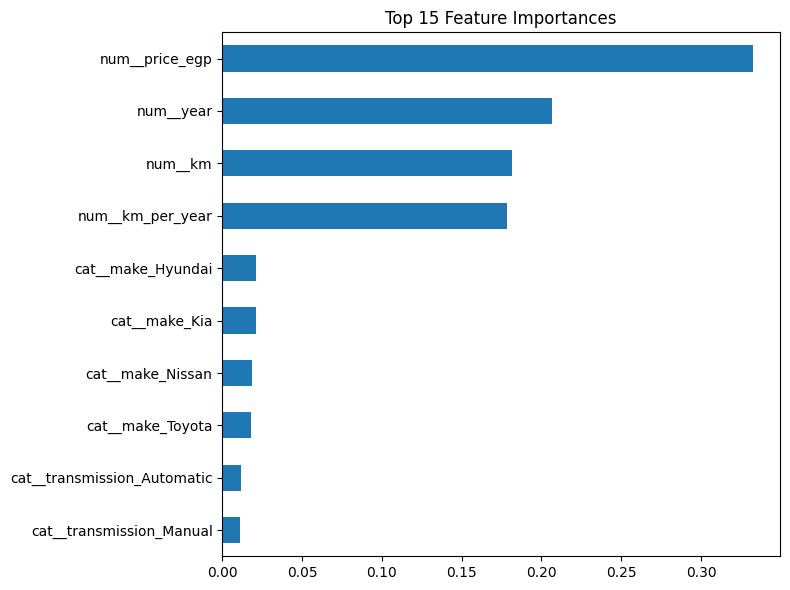

In [8]:
import matplotlib.pyplot as plt

names = rf_improved.named_steps['preprocessor'].get_feature_names_out()
imp = pd.Series(rf_improved.named_steps['classifier'].feature_importances_, index=names).sort_values(ascending=False)
imp.head(15).sort_values().plot(kind='barh', figsize=(8, 6))
plt.title('Top 15 Feature Importances')
plt.tight_layout()
plt.show()

In [10]:
print(y_train.head())
print(y_train.dtype)

354      Corolla
327     Fortuner
562      Qashqai
1630       Pride
1678      Carens
Name: model, dtype: object
object
